# Phase 4: inference calibration research

The user authorized Phase 4 after reviewing the descriptive estimator. This is a
**calibration study**, not a released uncertainty method. Stage 2 preparation,
Phase 3 slopes and the strict default remain unchanged. Standard 95% is excluded
from inference because its spatial support changes.

Software correctness, reference agreement and scientific calibration are separate.
A failed calibration screen means no application p-values, intervals or significance
maps may be released from this candidate. Read [the checkpoint](../phase_reports/PHASE_4_REPORT.md).

Run `tools/run_science_inference_study.py` and `tools/validate_inference_study.py` first.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, HTML, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/architecture/scope.v2.json").exists())
sys.path.insert(0, str(root / "packages/science"))
sys.path.insert(0, str(root / "tools"))
from src.inference import annual_inference
from run_science_inference_study import preserved_inputs
study = json.loads((root / "packages/science/phase_reports/PHASE_4_STUDY.json").read_text())
validation = json.loads((root / "packages/science/phase_reports/PHASE_4_VALIDATION.json").read_text())
assert validation["passed"]
assert preserved_inputs() == study["preserved_sha256"]
assert not study["application_release"]
print("Software tests:",validation["tests_run"],"pass:",validation["passed"])
print("Calibration research screen:",study["candidate_calibration"]["passes_research_screen"])
print("Application release:",study["application_release"])
print("Scenario-record evaluations (paired across block lengths):",study["monte_carlo_total_records"],"earlier files preserved:",study["preserved_file_count"])
def show(frame):display(HTML(frame.to_html(index=False,na_rep="withheld",float_format=lambda x:f"{x:.6f}")))

Software tests: 85 pass: True
Calibration research screen: False
Application release: False
Scenario-record evaluations (paired across block lengths): 24000 earlier files preserved: 98


## Candidate and admission rules

The point estimate remains exact Theil-Sen. For complete, consecutive annual
records with at least 20 observations, subtract the fitted slope, median-center
the residuals, and resample fixed-length circular residual blocks. The candidate
uses a basic bootstrap interval and a plus-one absolute-tail p-value. Four years
is the prespecified candidate block length, with 1/3/4/6-year sensitivity.

These choices are candidates, not a scientific default. Short, missing, gapped,
constant or residual-degenerate records do not receive fabricated uncertainty
values. Bootstrap samples are labeled synthetic replicates and never written
into NASA observations. All source values and missing data remain unchanged.

In [2]:
y=np.arange(24,dtype=float)+np.random.default_rng(6).normal(size=24)
y[3]=np.nan
original=y.copy()
short=annual_inference(np.arange(10),np.arange(2001,2011))
missing=annual_inference(y,np.arange(2001,2025))
constant=annual_inference(np.ones(24),np.arange(2001,2025))
np.testing.assert_array_equal(y,original)
show(pd.DataFrame([{"Example":name,"State":r["status"],"Valid observations":r["n_valid"],
                    "Candidate p":r["p_value_candidate"],"Candidate interval":r["interval_candidate"]}
                   for name,r in [("Short",short),("Missing annual value",missing),("Constant",constant)]]))

Example,State,Valid observations,Candidate p,Candidate interval
Short,insufficient_data,10,None,None
Missing annual value,insufficient_data,23,None,None
Constant,no_variation,24,None,None


## Correlated-null simulations and block sensitivity

Each scenario uses 500 independently simulated records with known slope zero,
stationary Gaussian AR(1) errors of marginal standard deviation one, and 999
bootstrap replicates. The true AR coefficient controls serial dependence. The
24-year experiments match the available annual record length; 48-year runs are
synthetic sensitivity studies, not additional NASA observations.

False-positive rate should be near the nominal 5%, and a nominal 95% interval
should cover the known true slope about 95% of the time. Wilson ranges describe
Monte Carlo uncertainty in these rates, not climate-slope uncertainty.

The same records are reused across block lengths. The 24,000 scenario-record evaluations are paired comparisons, not 24,000 independent datasets.

Years,True AR coefficient,Block years,False positive rate,False positive MC95,Interval coverage,Coverage MC95
24,0.000000,1,0.118000,"[0.092593, 0.149232]",0.884000,"[0.852958, 0.909186]"
24,0.000000,3,0.158000,"[0.128653, 0.192562]",0.836000,"[0.801005, 0.865871]"
24,0.000000,4,0.186000,"[0.154334, 0.222454]",0.824000,"[0.788186, 0.854874]"
24,0.000000,6,0.220000,"[0.185901, 0.258369]",0.776000,"[0.73743, 0.810361]"
24,0.400000,1,0.284000,"[0.246238, 0.325056]",0.716000,"[0.674944, 0.753762]"
24,0.400000,3,0.246000,"[0.210281, 0.285592]",0.754000,"[0.714408, 0.789719]"
24,0.400000,4,0.250000,"[0.214048, 0.289764]",0.740000,"[0.699826, 0.776514]"
24,0.400000,6,0.278000,"[0.240537, 0.318849]",0.722000,"[0.681151, 0.759463]"
24,0.700000,1,0.468000,"[0.424674, 0.511814]",0.530000,"[0.486191, 0.573352]"
24,0.700000,3,0.346000,"[0.305621, 0.388727]",0.646000,"[0.603116, 0.686658]"


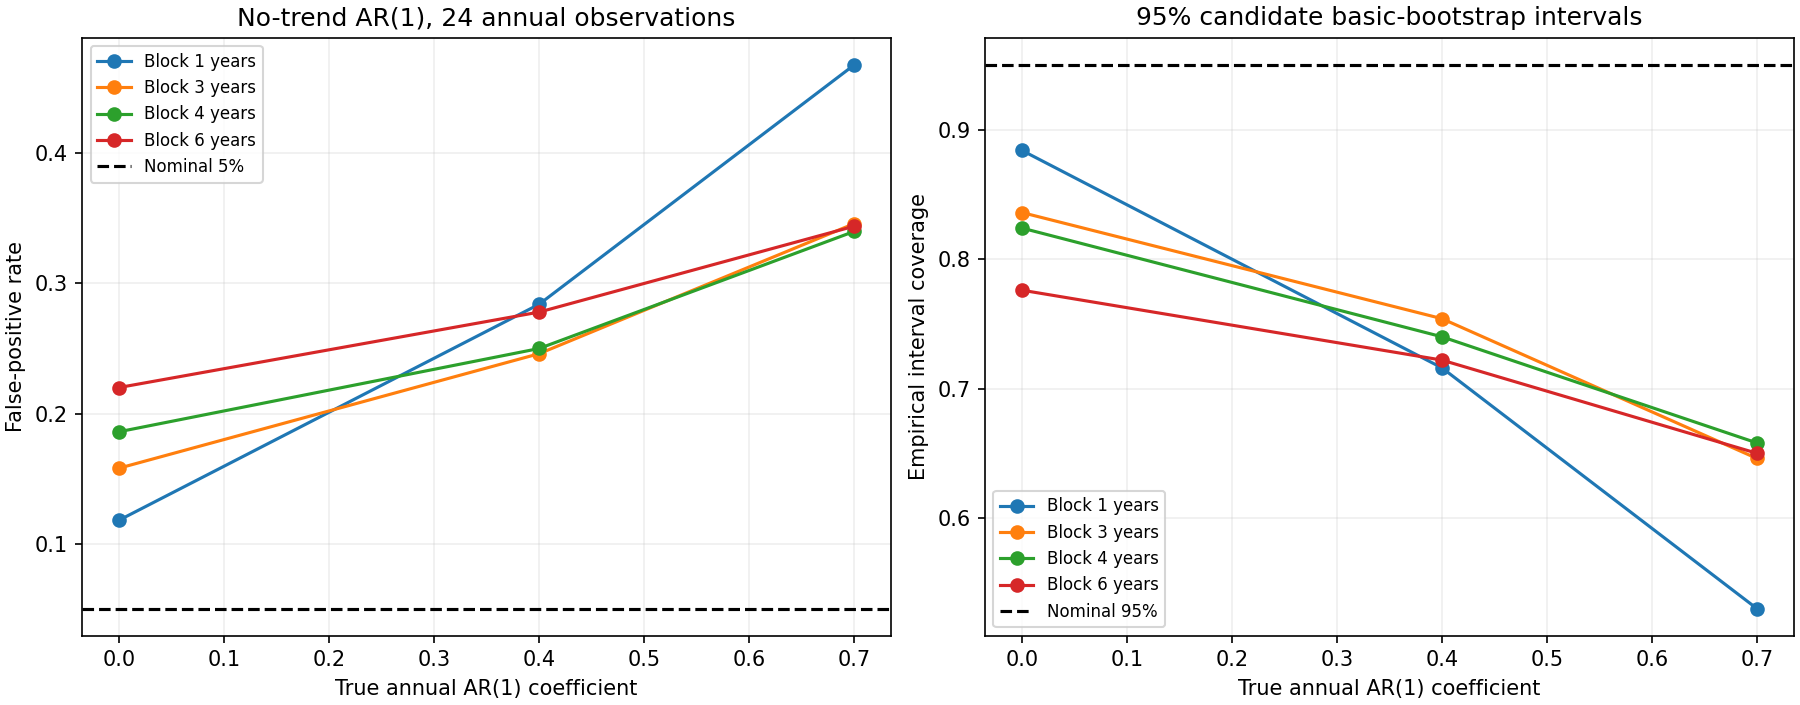

scenario,false_positive_upper_mc95,coverage_lower_mc95,passes_research_screen
annual_ar1_null_phi0.0_n24,0.222454,0.788186,False
annual_ar1_null_phi0.4_n24,0.289764,0.699826,False
annual_ar1_null_phi0.7_n24,0.382601,0.615356,False


In [3]:
null=[r for r in study["simulation_records"] if r["model"]=="annual_ar1" and r["true_slope_per_year"]==0]
show(pd.DataFrame([{"Years":r["n_years"],"True AR coefficient":r["phi"],"Block years":r["block_length_years"],
                    "False positive rate":r["rejection_rate"],"False positive MC95":r["rejection_mc95"],
                    "Interval coverage":r["coverage"],"Coverage MC95":r["coverage_mc95"]} for r in null]))
display(Image(filename=str(root/"data/derived/science_inference/phase_4/annual_calibration.png")))
show(pd.DataFrame(study["candidate_calibration"]["checks"]))

## Power, seasonality and an independent IID benchmark

Power is not an attractive property if the null false-positive rate is inflated.
The known alternatives have slope -0.08 or +0.08 units/year. Interpret rejection
rates alongside the null calibration and interval coverage, not as evidence of a
usable method. Additional monthly seasonal nulls are aggregated with the existing
complete-year day-weighted rule before applying annual inference.

The classical SciPy Sen interval and exact Kendall test below are an independent
IID benchmark on the same seeded null records. Their independence assumptions
are false for nonzero AR coefficients; they are not a dependence correction or
a replacement candidate selected after seeing the results.

In [4]:
power=[r for r in study["simulation_records"] if r["true_slope_per_year"]!=0]
show(pd.DataFrame([{"True slope":r["true_slope_per_year"],"AR coefficient":r["phi"],"Block years":r["block_length_years"],
                    "Power (uncalibrated candidate)":r["rejection_rate"],"Coverage":r["coverage"]} for r in power]))
seasonal=[r for r in study["simulation_records"] if r["model"]=="annualized_monthly_seasonal"]
show(pd.DataFrame([{"Monthly AR coefficient":r["monthly_phi"],"Block years":r["block_length_years"],
                    "False positive rate":r["rejection_rate"],"Coverage":r["coverage"]} for r in seasonal]))
show(pd.DataFrame(validation["classical_iid_reference_benchmark"]["rows"]))

True slope,AR coefficient,Block years,Power (uncalibrated candidate),Coverage
-0.080000,0.000000,3,0.838000,0.850000
-0.080000,0.000000,4,0.844000,0.820000
-0.080000,0.000000,6,0.866000,0.800000
0.080000,0.000000,3,0.844000,0.850000
0.080000,0.000000,4,0.860000,0.820000
0.080000,0.000000,6,0.876000,0.800000
-0.080000,0.400000,3,0.696000,0.828000
-0.080000,0.400000,4,0.692000,0.826000
-0.080000,0.400000,6,0.722000,0.788000
0.080000,0.400000,3,0.696000,0.828000


Monthly AR coefficient,Block years,False positive rate,Coverage
0.000000,3,0.144000,0.854000
0.000000,4,0.178000,0.816000
0.000000,6,0.210000,0.780000
0.700000,3,0.152000,0.844000
0.700000,4,0.174000,0.824000
0.700000,6,0.216000,0.774000


n_years,phi,replications,classical_iid_sen_coverage,coverage_mc95,classical_iid_kendall_false_positive_rate,false_positive_mc95,mean_interval_width,assumptions
24,0.000000,500,0.932000,"[0.906479, 0.950933]",0.074000,"[0.054161, 0.100335]",0.129071,independent observations; invalid as a dependence correction when phi is nonzero
24,0.400000,500,0.802000,"[0.764826, 0.834569]",0.214000,"[0.180303, 0.252058]",0.123710,independent observations; invalid as a dependence correction when phi is nonzero
24,0.700000,500,0.646000,"[0.603116, 0.686658]",0.364000,"[0.323011, 0.407062]",0.113127,independent observations; invalid as a dependence correction when phi is nonzero
48,0.000000,500,0.958000,"[0.936648, 0.972368]",0.042000,"[0.027632, 0.063352]",0.043387,independent observations; invalid as a dependence correction when phi is nonzero
48,0.400000,500,0.840000,"[0.805292, 0.869524]",0.160000,"[0.130476, 0.194708]",0.042310,independent observations; invalid as a dependence correction when phi is nonzero
48,0.700000,500,0.610000,"[0.566564, 0.651759]",0.390000,"[0.348241, 0.433436]",0.039855,independent observations; invalid as a dependence correction when phi is nonzero


## Multiplicity: arithmetic and assumptions

BH and BY adjusted p-values are checked against SciPy. Separate synthetic families
have valid Gaussian null p-values with independent, positively correlated, or
mixed-sign dependence. BY accommodates arbitrary dependence when individual
p-values are valid; neither correction repairs miscalibrated marginal p-values.

The mixed-family FDR is the mean false-discovery proportion across 2,000 independent
families, with Monte Carlo uncertainty. In all-null families it equals the chance
of any rejection. Simulations do not prove FDR control for an actual spatial field.

dependence,nonnull_fraction,method,fdr,fdr_mc95,power
independent,0.000000,BH,0.049000,"[0.040374, 0.059356]",withheld
independent,0.000000,BY,0.008000,"[0.00493, 0.012956]",withheld
independent,0.200000,BH,0.039673,"[0.037949, 0.041397]",0.608325
independent,0.200000,BY,0.006752,"[0.005783, 0.007722]",0.334150
positive_shared_factor,0.000000,BH,0.032500,"[0.025581, 0.041212]",withheld
positive_shared_factor,0.000000,BY,0.004500,"[0.002369, 0.008531]",withheld
positive_shared_factor,0.200000,BH,0.032873,"[0.02756, 0.038186]",0.573575
positive_shared_factor,0.200000,BY,0.005659,"[0.003423, 0.007894]",0.338012
signed_shared_factor,0.000000,BH,0.029000,"[0.0225, 0.037305]",withheld
signed_shared_factor,0.000000,BY,0.006500,"[0.003803, 0.01109]",withheld


Maximum adjusted-p reference difference: 3.3306690738754696e-16


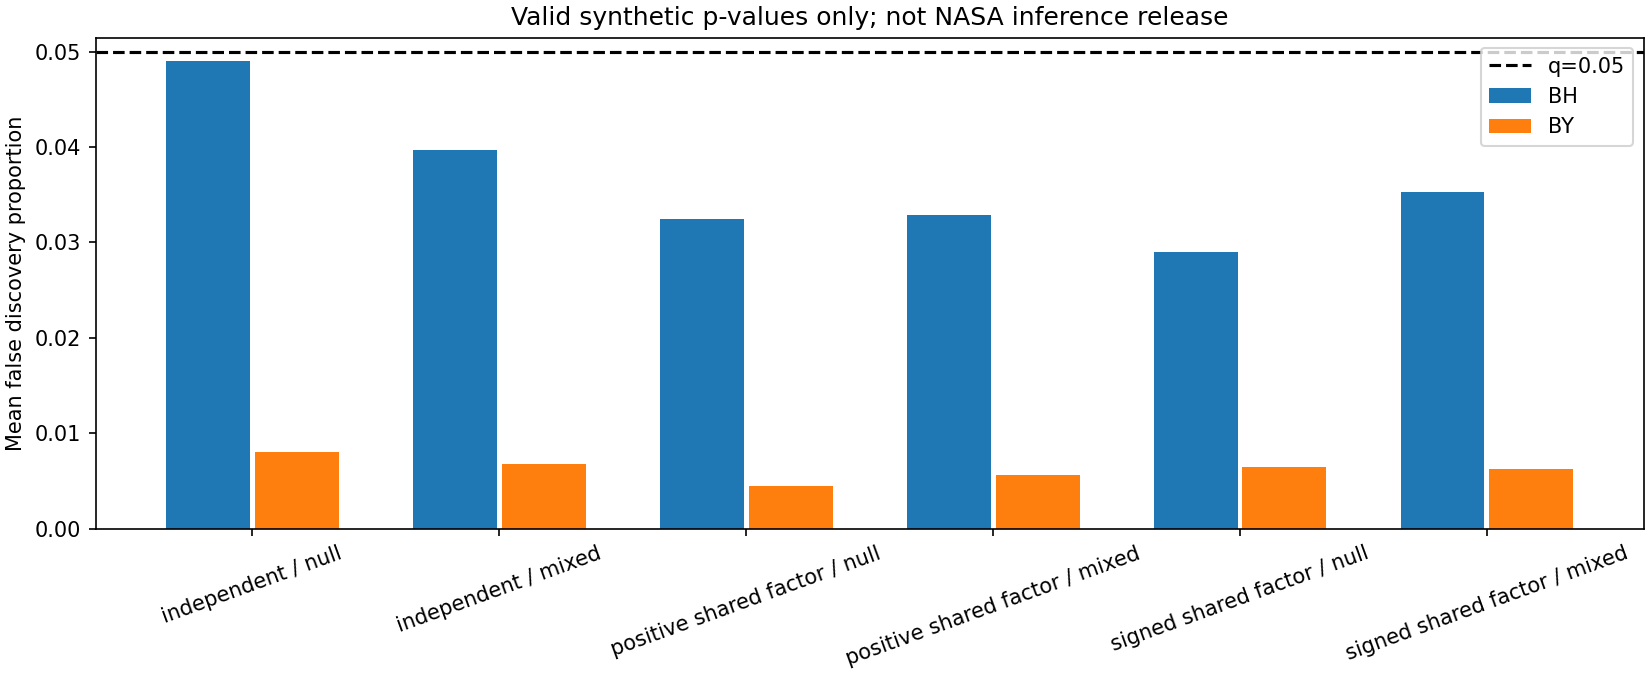

In [5]:
show(pd.DataFrame([{k:r[k] for k in ["dependence","nonnull_fraction","method","fdr","fdr_mc95","power"]}
                   for r in study["multiplicity_study"]["rows"]]))
print("Maximum adjusted-p reference difference:",study["multiplicity_study"]["max_reference_absolute_difference"])
display(Image(filename=str(root/"data/derived/science_inference/phase_4/synthetic_fdr.png")))

## NASA diagnostics remain outside the application

The following are experimental annual regional calculations for the twelve strict
inputs plus a separate Sahel Standard 100% comparison. They are displayed to
expose block-length sensitivity. The candidate's failed calibration cannot be
repaired by interpreting these values as validated evidence. Real multiplicity
adjustment, real-cell inference and all significance overlays remain withheld.
Standard 95% has no candidate p-value or interval here.

In [6]:
rows=[]
for r in study["nasa_candidate_diagnostics"]:
    if r["status"]=="candidate_diagnostic":
        rows.append({"Case":r["case"],"Block years":r["block_length_years"],"Slope/year":r["slope_per_year"],
                     "Units":r["units"],"Candidate p (not released)":r["p_value_candidate"],
                     "Candidate interval (not released)":r["interval_candidate"]})
show(pd.DataFrame(rows))
print("Standard 95%:",next(r for r in study["nasa_candidate_diagnostics"] if r["status"]=="inference_withheld"))
print("Real multiplicity:",study["real_multiplicity"])
print("Real-cell inference:",study["real_cell_inference"])

Case,Block years,Slope/year,Units,Candidate p (not released),Candidate interval (not released)
air_temperature__nile_corridor__strict_100,3,0.025330,K per year,0.002000,"[0.008237, 0.042602]"
air_temperature__nile_corridor__strict_100,4,0.025330,K per year,0.001000,"[0.009388, 0.043117]"
air_temperature__nile_corridor__strict_100,6,0.025330,K per year,0.001000,"[0.0128, 0.0425]"
soil_moisture__nile_corridor__strict_100,3,0.008890,kg m-2 per year,0.187500,"[-0.004926, 0.023085]"
soil_moisture__nile_corridor__strict_100,4,0.008890,kg m-2 per year,0.155500,"[-0.003535, 0.022454]"
soil_moisture__nile_corridor__strict_100,6,0.008890,kg m-2 per year,0.117000,"[-0.002001, 0.02089]"
precipitation__nile_corridor__strict_100,3,0.027555,mm per year,0.718500,"[-0.440187, 0.534985]"
precipitation__nile_corridor__strict_100,4,0.027555,mm per year,0.715500,"[-0.420715, 0.540238]"
precipitation__nile_corridor__strict_100,6,0.027555,mm per year,0.635500,"[-0.2816, 0.439459]"
vegetation_greenness__nile_corridor__strict_100,3,0.000124,1 per year,0.000500,"[0.000052, 0.000196]"


Standard 95%: {'case': 'vegetation_greenness__sahel_comparison__standard_95', 'status': 'inference_withheld', 'reason': 'Standard 95% remains experimental with changing spatial support; incomplete cell-years stay missing'}
Real multiplicity: withheld; adjustment cannot repair miscalibrated marginal p-values
Real-cell inference: withheld pending marginal calibration


## Review boundary

The study evaluates a versioned candidate; it does not certify an uncertainty
method or authorize Phase 5. Passing software tests and a trusted FDR comparison
are not substitutes for marginal test calibration. The default preparation,
prior slopes, missing values and readiness flags remain unchanged.

Review [PHASE_4_REPORT.md](../phase_reports/PHASE_4_REPORT.md). If the calibration
screen fails, retain descriptive Phase 3 outputs and continue method research
before releasing uncertainty, significance or spatial classifications.